# ENGR 418 — Facial Age Group Estimation
## Dataset inspection: Face-Age-10K

This notebook is the first data-preparation step for our project. We will load the Hugging Face dataset, inspect its labels and images, look for incomplete or unreadable examples, and create a reproducible stratified 70/15/15 split. **We will not train a model here.**

Run cells from top to bottom. The first download can take a while (the repository currently reports about 413 MB).

## 1. Dataset provenance, labels, and rights caveats

The dataset repository is [`prithivMLmods/Face-Age-10K`](https://huggingface.co/datasets/prithivMLmods/Face-Age-10K). Its dataset card describes 9,165 facial images, a single `train` split, 200×200 pixel images, and eight age-group labels. The card lists these groups: `age 01-10`, `age 11-20`, `age 21-30`, `age 31-40`, `age 41-55`, `age 56-65`, `age 66-80`, and `age 80 +`. The final two ranges meet at age 80 in the card wording; we preserve the labels exactly rather than silently changing their meaning.

**Provenance is not fully documented.** The repository contains one Parquet data file and a short card. Hugging Face tags it with `Synthetic`, but the card does not describe how images were generated, identify the source dataset(s), explain annotation or quality-control procedures, or confirm that every image is synthetic. Treat the tag as an indication that requires follow-up, not proof about every record. Age-group labels are categories supplied by the publisher; do not treat them as verified chronological ages.

**Licensing caveat:** Hugging Face displays `apache-2.0` for this repository. That repository-level license label does not by itself establish the rights, consent, privacy status, or permitted uses of the underlying faces, especially if images originated elsewhere. Before redistribution, publication, or any real-world use, review the dataset’s source and applicable rights with the instructor and consult the original image providers. This notebook does not make a legal determination.

Sources: [dataset card](https://huggingface.co/datasets/prithivMLmods/Face-Age-10K), [repository files](https://huggingface.co/datasets/prithivMLmods/Face-Age-10K/tree/main). Retrieved for notebook preparation on 2026-11-05.

## 2. Install and import the tools

We use Hugging Face `datasets` to load the repository, Pillow to inspect image files, pandas for tables, and Matplotlib for plots. If an import fails, uncomment and run the installation line, then restart the kernel.

In [1]:
# If needed, install dependencies in this notebook environment:
# %pip install -U datasets pandas matplotlib pillow scikit-learn

from datasets import load_dataset
from PIL import Image, UnidentifiedImageError
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import random
import numpy as np

DATASET_ID = "prithivMLmods/Face-Age-10K"
SEED = 418  # fixed seed makes the split repeatable
EXPECTED_LABELS = [
    "age 01-10", "age 11-20", "age 21-30", "age 31-40",
    "age 41-55", "age 56-65", "age 66-80", "age 80 +",
]

## 3. Load and describe the dataset

The publisher provides one split named `train`. That name describes the source repository; we will create our own train, validation, and test partitions later. First, inspect the feature schema, number of rows, and label names.

In [2]:
dataset = load_dataset(DATASET_ID)
source_data = dataset["train"]

print(dataset)
print(f"\nRows in publisher's train split: {len(source_data):,}")
print("Features:", source_data.features)

label_feature = source_data.features["label"]
label_names = label_feature.names if hasattr(label_feature, "names") else None
print("\nLabel names from the loaded schema:", label_names)

README.md:   0%|          | 0.00/1.16k [00:00<?, ?B/s]

C:\Users\ASUS\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ASUS\.cache\huggingface\hub\datasets--prithivMLmods--Face-Age-10K. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


dataset/0000.parquet: reconstructing file:   0%|          |  0.00B /  413MB            

dataset/0000.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/9165 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 9165
    })
})

Rows in publisher's train split: 9,165
Features: {'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['age 01-10', 'age 11-20', 'age 21-30', 'age 31-40', 'age 41-55', 'age 56-65', 'age 66-80', 'age 80 +'])}

Label names from the loaded schema: ['age 01-10', 'age 11-20', 'age 21-30', 'age 31-40', 'age 41-55', 'age 56-65', 'age 66-80', 'age 80 +']


## 4. Display 20 sample images with labels

A visual check helps catch surprising content, mismatched labels, or broken images. We use a fixed random seed so the same 20 rows are selected each run. This is a small inspection sample, not a quality audit of every face.

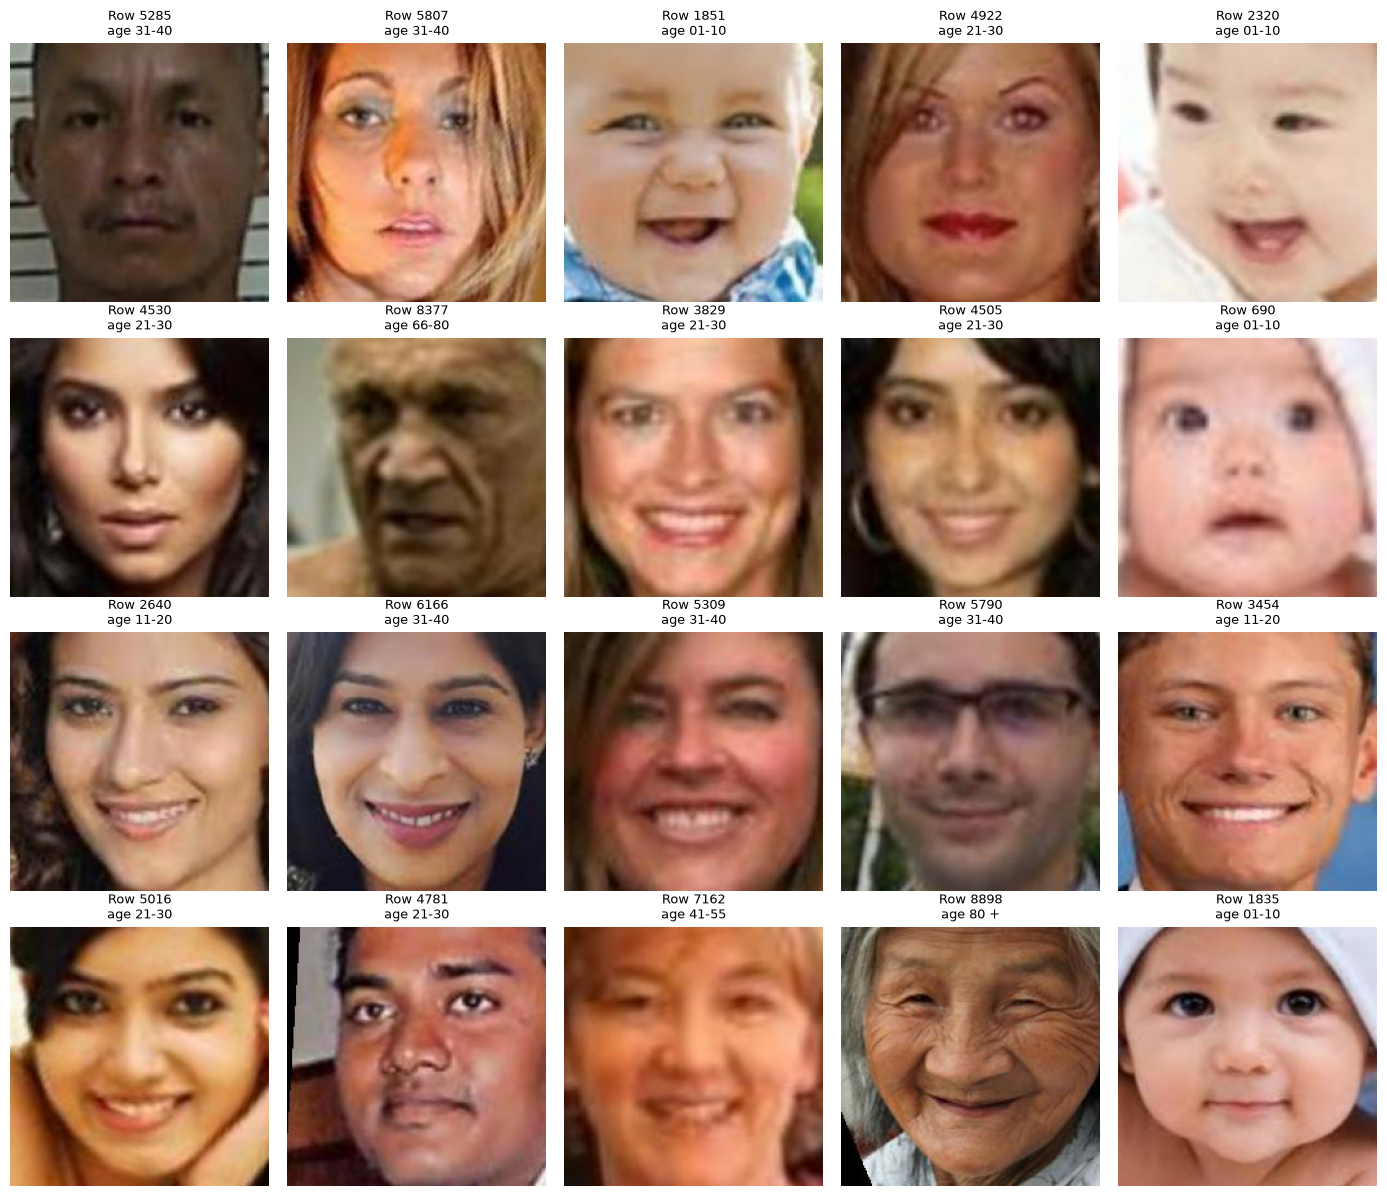

In [3]:
sample_rng = random.Random(SEED)
sample_indices = sample_rng.sample(range(len(source_data)), k=min(20, len(source_data)))

fig, axes = plt.subplots(4, 5, figsize=(14, 12))
for ax, row_index in zip(axes.flat, sample_indices):
    row = source_data[row_index]
    image = row["image"]
    ax.imshow(image)
    raw_label = row["label"]
    if label_names is not None and isinstance(raw_label, (int, np.integer)):
        shown_label = label_names[int(raw_label)]
    else:
        shown_label = str(raw_label)
    ax.set_title(f"Row {row_index}\n{shown_label}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Count and plot the eight age classes

Class counts tell us whether the categories are balanced. We display every expected label, including a zero count if one is absent. If the loaded label schema differs from the card, pause and investigate before proceeding.

Counts by documented class:


,count
age 01-10,2474
age 11-20,1181
age 21-30,1523
age 31-40,1010
age 41-55,1181
age 56-65,799
age 66-80,653
age 80 +,344


Unexpected labels: []
Total labels counted: 9165


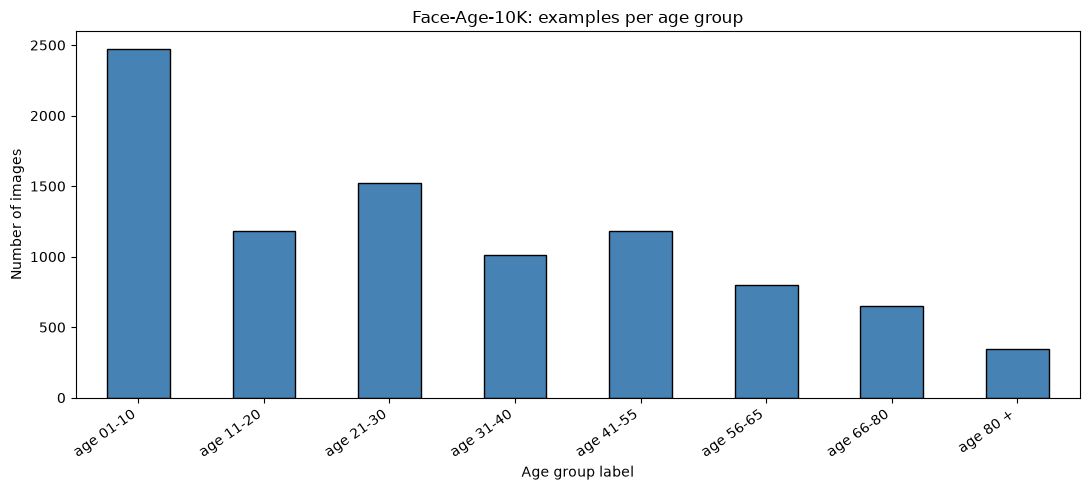

In [4]:
def label_text(value):
    # Hugging Face ClassLabel columns are commonly returned as integer IDs.
    if label_names is not None and isinstance(value, (int, np.integer)):
        return label_names[int(value)]
    return str(value)

all_labels = [label_text(value) for value in source_data["label"]]
label_counts = Counter(all_labels)
unexpected_labels = sorted(set(all_labels) - set(EXPECTED_LABELS))
counts = pd.Series({name: label_counts.get(name, 0) for name in EXPECTED_LABELS}, name="count")
print("Counts by documented class:")
display(counts.to_frame())
print("Unexpected labels:", unexpected_labels)
print("Total labels counted:", sum(label_counts.values()))

ax = counts.plot(kind="bar", figsize=(11, 5), color="steelblue", edgecolor="black")
ax.set_title("Face-Age-10K: examples per age group")
ax.set_xlabel("Age group label")
ax.set_ylabel("Number of images")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 6. Check dimensions, color channels, and invalid rows

We examine every row. A missing image, an object that is not a Pillow image, an image that cannot be read, a zero-sized image, a missing label, or a label outside the documented eight classes is flagged. Image mode is recorded as stored; `RGB`, `L` (grayscale), and `RGBA` are examples of modes. We do not silently convert images during this inspection.

This pass decodes the images and may take a little time. The resulting `inspection` table keeps the original row number so later partitions can refer back to the dataset.

In [5]:
inspection_rows = []
for row_index, row in enumerate(source_data):
    image = row.get("image")
    label = label_text(row.get("label")) if row.get("label") is not None else None
    issues = []
    width = height = channels = None
    mode = None

    if image is None:
        issues.append("missing image")
    elif not isinstance(image, Image.Image):
        issues.append(f"unexpected image type: {type(image).__name__}")
    else:
        try:
            image.load()  # force decoding so truncated/corrupt data is caught
            width, height = image.size
            mode = image.mode
            channels = len(image.getbands())
            if width <= 0 or height <= 0:
                issues.append("zero-sized image")
        except (OSError, ValueError, UnidentifiedImageError) as error:
            issues.append(f"unreadable image: {type(error).__name__}")

    if label is None:
        issues.append("missing label")
    elif label not in EXPECTED_LABELS:
        issues.append(f"unknown label: {label}")

    inspection_rows.append({
        "row_index": row_index, "label": label, "width": width, "height": height,
        "mode": mode, "channels": channels, "issues": issues, "valid": len(issues) == 0,
    })

inspection = pd.DataFrame(inspection_rows)
print(f"Rows inspected: {len(inspection):,}")
print(f"Valid rows: {inspection['valid'].sum():,}")
print(f"Rows with one or more issues: {(~inspection['valid']).sum():,}")
print("\nImage dimension combinations:")
display(inspection.groupby(["width", "height"], dropna=False).size().rename("count").to_frame())
print("Image modes:")
display(inspection["mode"].value_counts(dropna=False).rename("count").to_frame())
print("Channel counts:")
display(inspection["channels"].value_counts(dropna=False).sort_index().rename("count").to_frame())

invalid_rows = inspection.loc[~inspection["valid"]]
display(invalid_rows.head(20))
if len(invalid_rows) == 0:
    print("No missing, unreadable, zero-sized, or undocumented-label rows were found.")

Rows inspected: 9,165
Valid rows: 9,165
Rows with one or more issues: 0

Image dimension combinations:


,,count
width,height,
200,200,9165


Image modes:


,count
mode,
RGB,9165


Channel counts:


,count
channels,
3,9165


,row_index,label,width,height,mode,channels,issues,valid


No missing, unreadable, zero-sized, or undocumented-label rows were found.


## 7. Prepare a stratified 70/15/15 split

Stratification keeps each age group represented in roughly the same proportions in all three partitions. We split only the rows that passed the inspection above. The two-stage approach first reserves 15% for test, then takes validation from the remaining 85%, giving 15% of the full valid set (15/85 of the remainder). A fixed random seed makes the indices repeatable.

These are row indices, not copied image files. Keeping indices avoids making another large copy of the dataset. We verify that the partitions do not overlap and compare their class proportions. This only prepares data; it does not train or evaluate a model.

In [6]:
from sklearn.model_selection import train_test_split

valid_table = inspection.loc[inspection["valid"], ["row_index", "label"]].copy()
if valid_table.empty:
    raise ValueError("There are no valid rows to split. Review the inspection output.")

# Every class must have at least 2 examples for this two-stage stratified split.
valid_class_counts = valid_table["label"].value_counts()
too_small = valid_class_counts[valid_class_counts < 2]
if len(too_small):
    raise ValueError(f"Cannot stratify classes with fewer than 2 valid rows: {too_small.to_dict()}")

train_val_indices, test_indices = train_test_split(
    valid_table["row_index"].to_numpy(), test_size=0.15, random_state=SEED,
    stratify=valid_table["label"].to_numpy()
)
train_val_table = valid_table.set_index("row_index").loc[train_val_indices].reset_index()
train_indices, val_indices = train_test_split(
    train_val_table["row_index"].to_numpy(), test_size=(0.15 / 0.85), random_state=SEED,
    stratify=train_val_table["label"].to_numpy()
)

split_indices = {"train": train_indices, "validation": val_indices, "test": test_indices}
sets = {name: set(indices.tolist()) for name, indices in split_indices.items()}
assert sets["train"].isdisjoint(sets["validation"])
assert sets["train"].isdisjoint(sets["test"])
assert sets["validation"].isdisjoint(sets["test"])
assert len(set.union(*sets.values())) == len(valid_table)

print("Partition sizes (rows and percent of valid data):")
for name, indices in split_indices.items():
    print(f"{name:10s}: {len(indices):5,} ({len(indices) / len(valid_table):.1%})")

label_by_index = valid_table.set_index("row_index")["label"]
split_labels = pd.DataFrame({
    name: label_by_index.loc[indices].value_counts(normalize=True)
    for name, indices in split_indices.items()
}).reindex(EXPECTED_LABELS, fill_value=0)
print("\nClass proportions within each partition:")
display((100 * split_labels).round(1).rename_axis("age group").rename(columns=lambda name: f"{name} %"))

# Save indices in memory for later project notebooks; no model is created here.
print("\nSplit indices are ready in `split_indices` for later use.")

Partition sizes (rows and percent of valid data):
train     : 6,415 (70.0%)
validation: 1,375 (15.0%)
test      : 1,375 (15.0%)

Class proportions within each partition:


,train %,validation %,test %
age group,,,
age 01-10,27.0,27.0,27.0
age 11-20,12.9,12.9,12.9
age 21-30,16.6,16.7,16.6
age 31-40,11.0,11.0,11.1
age 41-55,12.9,12.9,12.9
age 56-65,8.7,8.7,8.7
age 66-80,7.1,7.1,7.1
age 80 +,3.7,3.8,3.8



Split indices are ready in `split_indices` for later use.


## 8. What we learned and what remains uncertain

After running this notebook, record any observed class imbalance, unusual image modes or dimensions, invalid rows, and the final split sizes in the project report. A successful image decode only confirms that a file can be opened; it does not verify a person’s age, image consent, demographic representativeness, or label accuracy.

Before model development, the team should review the provenance and intended-use limitations with the course instructor. In particular, confirm whether the synthetic tag describes the full dataset and how the labels were produced. No training is performed in this notebook.